# Homework 2: 影像分類，使用 PyTorch

**本地執行版本**：由作業範例 `hw2_sample.ipynb` 修改，將 Colab 專用的 `!wget` / `!tar` / `!md5sum` 改為 Python 寫法，可在 Windows 本地執行。

<!-- 若有使用生成式 AI 工具，請依作業規定在此與報告中註明 -->

In [1]:
# [本地版] 執行環境資訊（報告需填寫）
import platform, sys
import torch

print("OS:", platform.platform())
print("CPU:", platform.processor())
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

OS: Windows-11-10.0.26300-SP0
CPU: Intel64 Family 6 Model 186 Stepping 2, GenuineIntel
Python: 3.12.2
PyTorch: 2.11.0+cu128
GPU: NVIDIA GeForce RTX 4070 Laptop GPU


## 下載 CIFAR-10 資料集

In [2]:
# [本地版] Windows 沒有 wget，改用 Python 下載；已下載過就跳過
# 如果下載很慢，請至 E-Learning 下載後放到此資料夾
import os
import urllib.request

CIFAR_URL = "https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz"
CIFAR_TAR = "cifar-10-python.tar.gz"

if not os.path.exists(CIFAR_TAR):
    urllib.request.urlretrieve(CIFAR_URL, CIFAR_TAR)
print(CIFAR_TAR, os.path.getsize(CIFAR_TAR), "bytes")

cifar-10-python.tar.gz 170498071 bytes


In [3]:
# [本地版] 用 tarfile 解壓縮（等同 tar -xvf）；已解壓過就跳過
import tarfile

if not os.path.isdir("cifar-10-batches-py"):
    with tarfile.open(CIFAR_TAR, "r:gz") as tar:
        tar.extractall(filter="data")
print(os.listdir("cifar-10-batches-py"))

['batches.meta', 'data_batch_1', 'data_batch_2', 'data_batch_3', 'data_batch_4', 'data_batch_5', 'readme.html', 'test_batch']


In [4]:
# [本地版] 用 hashlib 檢查 md5（等同 md5sum）
# 理論上應該是 c58f30108f718f92721af3b95e74349a
import hashlib

with open(CIFAR_TAR, "rb") as f:
    print(hashlib.md5(f.read()).hexdigest())

c58f30108f718f92721af3b95e74349a


In [5]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from typing import Tuple
from PIL import Image
import torch
import torchvision
import os
from sklearn.metrics import accuracy_score

In [6]:
# 觀察 CIFAR-10 的類別

with open("cifar-10-batches-py/batches.meta", "rb") as f:
    label_names = pickle.load(f, encoding='bytes')[b'label_names']
    label_names = [label.decode("utf-8") for label in label_names]

print(label_names)

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 資料前處理
- 我們再來會用到的檔案是 `data_batch_n` (n=1~5), `test_batch` 等資料
- 因此，我們需要先觀察一下它們的內容


In [7]:
def unpickle(file: str) -> dict:
    with open(file, 'rb') as f:
        dict = pickle.load(f, encoding='bytes')
    return dict

In [8]:
tmp = unpickle("cifar-10-batches-py/data_batch_1")
print(type(tmp))
print(tmp.keys())

<class 'dict'>
dict_keys([b'batch_label', b'labels', b'data', b'filenames'])


In [9]:
print(tmp[b'data'].shape)
print(tmp[b'labels'])
print(type(tmp[b'labels']))
print()
print(tmp[b'data'][0].shape)
print(tmp[b'data'][0])
print(type(tmp[b'data']))

(10000, 3072)
[6, 9, 9, 4, 1, 1, 2, 7, 8, 3, 4, 7, 7, 2, 9, 9, 9, 3, 2, 6, 4, 3, 6, 6, 2, 6, 3, 5, 4, 0, 0, 9, 1, 3, 4, 0, 3, 7, 3, 3, 5, 2, 2, 7, 1, 1, 1, 2, 2, 0, 9, 5, 7, 9, 2, 2, 5, 2, 4, 3, 1, 1, 8, 2, 1, 1, 4, 9, 7, 8, 5, 9, 6, 7, 3, 1, 9, 0, 3, 1, 3, 5, 4, 5, 7, 7, 4, 7, 9, 4, 2, 3, 8, 0, 1, 6, 1, 1, 4, 1, 8, 3, 9, 6, 6, 1, 8, 5, 2, 9, 9, 8, 1, 7, 7, 0, 0, 6, 9, 1, 2, 2, 9, 2, 6, 6, 1, 9, 5, 0, 4, 7, 6, 7, 1, 8, 1, 1, 2, 8, 1, 3, 3, 6, 2, 4, 9, 9, 5, 4, 3, 6, 7, 4, 6, 8, 5, 5, 4, 3, 1, 8, 4, 7, 6, 0, 9, 5, 1, 3, 8, 2, 7, 5, 3, 4, 1, 5, 7, 0, 4, 7, 5, 5, 1, 0, 9, 6, 9, 0, 8, 7, 8, 8, 2, 5, 2, 3, 5, 0, 6, 1, 9, 3, 6, 9, 1, 3, 9, 6, 6, 7, 1, 0, 9, 5, 8, 5, 2, 9, 0, 8, 8, 0, 6, 9, 1, 1, 6, 3, 7, 6, 6, 0, 6, 6, 1, 7, 1, 5, 8, 3, 6, 6, 8, 6, 8, 4, 6, 6, 1, 3, 8, 3, 4, 1, 7, 1, 3, 8, 5, 1, 1, 4, 0, 9, 3, 7, 4, 9, 9, 2, 4, 9, 9, 1, 0, 5, 9, 0, 8, 2, 1, 2, 0, 5, 6, 3, 2, 7, 8, 8, 6, 0, 7, 9, 4, 5, 6, 4, 2, 1, 1, 2, 1, 5, 9, 9, 0, 8, 4, 1, 1, 6, 3, 3, 9, 0, 7, 9, 7, 7, 9, 1, 5, 1, 6, 6, 8

### 將影像儲存於對應的類別資料夾

In [10]:
def save_images_from_batch(
    batch_data: np.ndarray,
    batch_labels: list,
    batch_idx: int,
    split: str,
    output_dir: str,
):
    for i in range(len(batch_data)):
        img_array = batch_data[i] # 每組 batch 的 shape: 張數 x 3096
        label = batch_labels[i]

        # TODO1: 將 img_array 轉成 3x32x32，再轉成 (Height, Width, Channel) 格式
        # [AI 輔助] 此段由 Claude (Anthropic) 協助撰寫
        img = img_array.reshape(3, 32, 32).transpose(1, 2, 0)  # (C, H, W) -> (H, W, C)
        img = Image.fromarray(img) # 將數值資料轉為影像資料

        # 建立類別資料夾，讓影像可以存到各自的類別資料夾之中。
        class_dir = os.path.join(output_dir, split, str(label))
        os.makedirs(class_dir, exist_ok=True)
        # 因為這個 for loop 一次只會取一筆資料，因此需要 exist_ok=True
        # training 資料夾階層可以是 cifar10/train/`class_id`/train_n_0000.png
        # test 資料夾階層可以是 cifar10/test/`class_id`/test_n_0000.png

        img_filename = os.path.join(class_dir, f"{split}_{batch_idx}_{i:04d}.png")
        img.save(img_filename)

In [11]:
def convert_raw_to_images(
    cifar_dir: str = "cifar-10-batches-py",
    output_dir: str = "cifar10",
):
    os.makedirs(output_dir, exist_ok=True)

    # 處理訓練集
    for i in range(1, 6):
        batch = unpickle(os.path.join(cifar_dir, f"data_batch_{i}"))
        data = batch[b'data']
        labels = batch[b'labels']
        save_images_from_batch(
            batch_data=data,
            batch_labels=labels,
            batch_idx=i,
            split="train",
            output_dir=output_dir,
        )

    # 處理測試集
    test_batch = unpickle(os.path.join(cifar_dir, "test_batch"))
    save_images_from_batch(
        batch_data=test_batch[b'data'],
        batch_labels=test_batch[b'labels'],
        batch_idx=0,
        split="test",
        output_dir=output_dir,
    )

In [12]:
# 執行資料前處理
# [本地版] cifar10/ 已存在就跳過，避免重跑時重寫 6 萬張圖
if not os.path.isdir("cifar10"):
    convert_raw_to_images()
print({split: sum(len(files) for _, _, files in os.walk(os.path.join("cifar10", split))) for split in ["train", "test"]})

{'train': 50000, 'test': 10000}


處理後的資料夾階層將如下所示
```bash
cifar10/
├── train/
│   ├── 0/
│   │   ├── train_0_0001.png
│   │   ├── train_0_0002.png
│   │   └── ...
│   ├── 1/
│   ├── 2/
│   ├── 3/
│   ├── 4/
│   ├── 5/
│   ├── 6/
│   ├── 7/
│   ├── 8/
│   └── 9/
│
└── test/
    ├── 0/
    ├── 1/
    ├── ...
    └── 9/
```

## 建立 PyTorch Dataset

```python
# 繼承 torch.utils.data.Dataset
class CIFAR10ImageFolder(torch.utils.data.Dataset):
    def __init__(self, root_dir: str, transform=None):
        """
        root_dir: 資料夾路徑，例如 'cifar10/train'
        transform: torchvision.transforms 用來轉換 PIL 圖片
        """
    return

    def __getitem__(self, idx: int):
        return

    def __len__(self):
        return
```

In [13]:
from concurrent.futures import ThreadPoolExecutor


def load_image(path: str) -> Image.Image:
    with Image.open(path) as img:
        return img.convert('RGB')  # convert 會複製一份，檔案可以馬上關閉


class CIFAR10ImageFolder(torch.utils.data.Dataset):
    def __init__(self, root_dir: str, transform=None):
        """
        root_dir: 資料夾路徑，例如 'cifar10/train'
        transform: torchvision.transforms 用來轉換 PIL 圖片
        """
        self.root_dir = root_dir
        self.transform = transform
        self.image_paths = []
        self.labels = []

        # 列出 `root_dir` 底下有哪些類別資料夾，並由小至大排序
        class_names = sorted(os.listdir(root_dir))
        for idx, class_name in enumerate(class_names):
            class_folder = os.path.join(root_dir, class_name)
            if not os.path.isdir(class_folder):
                continue

            for filename in os.listdir(class_folder):
                if filename.endswith(('.png', '.jpg')):
                    # 將所有的檔案路徑都收集到 `self.image_paths`
                    self.image_paths.append(os.path.join(class_folder, filename))
                    # 將所有的 label_id 都收集到 `self.labels`
                    self.labels.append(idx)

        # [改進] 一次把所有影像讀進記憶體（CIFAR-10 約 150MB），避免每個 epoch 重讀 6 萬個小檔案
        # 讀檔是 I/O 密集，用多執行緒加速；在 Windows notebook 中執行緒不會有 num_workers 的問題
        # [AI 輔助] 此段由 Claude (Anthropic) 協助撰寫
        with ThreadPoolExecutor(max_workers=16) as pool:
            self.images = list(pool.map(load_image, self.image_paths))

    def __getitem__(self, idx: int):
        image = self.images[idx]  # [改進] 直接從記憶體取，不再 Image.open
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label # 回傳影像資料與標籤

    def __len__(self):
        return len(self.image_paths)

In [14]:
# 定義資料數值轉換
# [AI 輔助] 此段由 Claude (Anthropic) 協助撰寫
# CIFAR-10 訓練集各通道的平均值與標準差
CIFAR10_MEAN = [0.4914, 0.4822, 0.4465]
CIFAR10_STD = [0.2470, 0.2435, 0.2616]

# [改進] 訓練集使用資料擴增：隨機裁切（先補 4 pixel 再裁回 32x32）+ 隨機水平翻轉
train_transform = torchvision.transforms.Compose([
    torchvision.transforms.RandomCrop(32, padding=4),
    torchvision.transforms.RandomHorizontalFlip(),
    torchvision.transforms.ToTensor(),  # (HWC, uint8) → (CHW, float32 [0,1])
    torchvision.transforms.Normalize(mean=CIFAR10_MEAN, std=CIFAR10_STD),
])

# 驗證集 / 測試集不做擴增
test_transform = torchvision.transforms.Compose([
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(mean=CIFAR10_MEAN, std=CIFAR10_STD),
])

In [15]:
# 建立 Dataset
# train 先不給 transform，切完 validation 後再分別套上 train_transform / test_transform
full_train_dataset = CIFAR10ImageFolder(root_dir='cifar10/train')
test_dataset = CIFAR10ImageFolder(root_dir='cifar10/test', transform=test_transform)

In [16]:
# [改進] 直接取 Dataset 收集好的 labels，不必逐張讀圖
train_labels = full_train_dataset.labels
test_labels = test_dataset.labels

In [17]:
import collections
print(collections.Counter(train_labels))
print(collections.Counter(test_labels))

Counter({0: 5000, 1: 5000, 2: 5000, 3: 5000, 4: 5000, 5: 5000, 6: 5000, 7: 5000, 8: 5000, 9: 5000})
Counter({0: 1000, 1: 1000, 2: 1000, 3: 1000, 4: 1000, 5: 1000, 6: 1000, 7: 1000, 8: 1000, 9: 1000})


In [18]:
# 從 train_dataset 切出 validation_dataset
# [AI 輔助] 此段由 Claude (Anthropic) 協助撰寫
from torch.utils.data import random_split

SEED = 42
torch.manual_seed(SEED)  # [改進] 固定亂數種子，讓結果可重現

validation_ratio = 0.2
total_len = len(full_train_dataset)
val_size = int(validation_ratio * total_len)
train_size = total_len - val_size

train_split, val_split = random_split(
    full_train_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED),
)


class TransformSubset(torch.utils.data.Dataset):
    """[改進] random_split 切出的 train / val 共用同一個 Dataset，
    若直接設 transform 會讓 val 也被資料擴增，因此包一層讓兩者各自套用 transform"""

    def __init__(self, dataset, indices, transform):
        self.dataset = dataset
        self.indices = indices
        self.transform = transform

    def __getitem__(self, idx: int):
        image, label = self.dataset[self.indices[idx]]
        return self.transform(image), label

    def __len__(self):
        return len(self.indices)


train_dataset = TransformSubset(full_train_dataset, train_split.indices, train_transform)
val_dataset = TransformSubset(full_train_dataset, val_split.indices, test_transform)
train_eval_dataset = TransformSubset(full_train_dataset, train_split.indices, test_transform)  # 計算訓練集準確率用（不擴增）
print(len(train_dataset), len(val_dataset), len(test_dataset))

40000 10000 10000


## 超參數

In [19]:
LR = 0.001
weight_decay = 5e-4  # [改進] L2 正則化
train_batch_size = 128
test_batch_size = 256
num_epochs = 30

## 建立 DataLoader

> **[本地版提醒]** Windows 的 Jupyter 中，`CIFAR10ImageFolder` 定義在 notebook 裡，DataLoader 的 `num_workers` 請設 `0`（預設值），設 >0 會卡住或報錯。

In [20]:
# TODO2: 建立 DataLoader (train / valid / test)
# [AI 輔助] 此段由 Claude (Anthropic) 協助撰寫
# Windows notebook 下 num_workers 維持 0
train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=train_batch_size, shuffle=True
)
val_loader = torch.utils.data.DataLoader(
    val_dataset, batch_size=test_batch_size, shuffle=False
)
test_loader = torch.utils.data.DataLoader(
    test_dataset, batch_size=test_batch_size, shuffle=False  # 不可 shuffle，順序要和 test_labels 對齊
)

# 簡單驗證一個 batch
for images, labels in test_loader:
    print("Image shape:", images.shape)  # [B, 3, 32, 32]
    print("Label shape:", labels.shape)  # [B]
    break

Image shape: torch.Size([256, 3, 32, 32])
Label shape: torch.Size([256])


Text(0.5, 1.0, 'airplane')

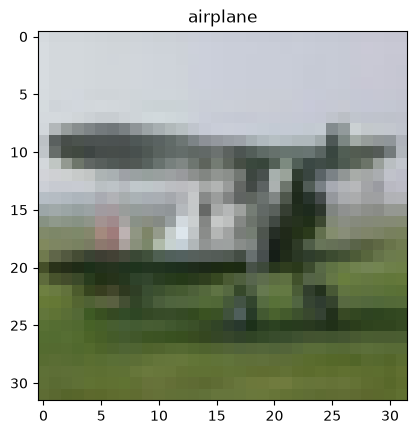

In [21]:
# 驗證一個 example
example_img, example_label = val_dataset[0]

example = example_img.numpy() # shape: (3, 32, 32)，因為要印出影像，所以需要先轉回 numpy
example = example.transpose(1, 2, 0) # shape: (32, 32, 3)，把 channels 放在最後面
example = example * np.array(CIFAR10_STD) + np.array(CIFAR10_MEAN)  # 反正規化回 [0, 1]

plt.imshow(Image.fromarray((example.clip(0, 1) * 255).astype('uint8')))
plt.title(label_names[example_label])

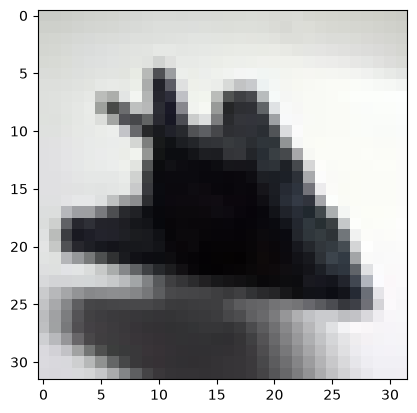

In [22]:
# 你也可以單純指定一張影像的位置，來印出它
image = Image.open('cifar10/train/0/train_1_0029.png')
plt.imshow(image)

## 建立模型
- 影像在進行每層 convolution 後的 feature map 大小公式：
$$
\mathrm{output\_size} = \frac{\mathrm{input\_size} - \mathrm{kernel\_size} + 2*\mathrm{padding}}{\mathrm{stride}} + 1
$$

In [23]:
class SimpleCNN(torch.nn.Module):
    def __init__(self, num_classes=10, fc_hidden_size=256, dropout_ratio=0.5):
        super().__init__()

        self.conv1 = torch.nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
        self.conv2 = torch.nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = torch.nn.Conv2d(64, 128, kernel_size=3, padding=1)

        self.pool = torch.nn.MaxPool2d(kernel_size=2, stride=2) # 2x2 pooling

        self.fc1 = torch.nn.Linear(128 * 4 * 4, fc_hidden_size)
        self.fc2 = torch.nn.Linear(fc_hidden_size, num_classes)
        self.relu = torch.nn.ReLU() # 非線性轉換

        self.dropout = torch.nn.Dropout(dropout_ratio)

    def forward(self, x):
        # [AI 輔助] 此段由 Claude (Anthropic) 協助撰寫
        # TODO3: 加入 conv1 layer
        x = self.relu(self.conv1(x))
        x = self.pool(x)
        # conv1: output_size = (32 - 3 + 2 * 1) / 1 + 1 = 32
        # pooling: output_size = (32 - 3 + 2 * 0) / 2 + 1 = 15.5 (進位為 16)

        # TODO3: 加入 conv2 layer
        x = self.relu(self.conv2(x))
        x = self.pool(x)
        # conv2: output_size = (16 - 3 + 2 * 1) / 1 + 1 = 16
        # pooling: output_size = (16 - 3 + 2 * 0) / 2 + 1 = 7.5 (進位為 8)

        # TODO3: 加入 conv3 layer
        x = self.relu(self.conv3(x))
        x = self.pool(x)   # shape: (B, 128, 4, 4)
        # conv3: output_size = (8 - 3 + 2 * 1) / 1 + 1 = 8
        # pooling: output_size = (8 - 3 + 2 * 0) / 2 + 1 = 3.5 (進位為 4)

        x = x.view(x.size(0), -1)  # Flatten, shape: (B, 128*4*4)
        x = self.dropout(self.relu(self.fc1(x)))  # TODO3: 加入 fc1 layer
        x = self.fc2(x)  # TODO3: 加入 fc2 layer
        return x

### 改良模型：ImprovedCNN
- 參考 VGG 的設計：每個 stage 兩層 3x3 conv，再接 2x2 max pooling，共 3 個 stage（32→16→8→4）
- 每層 conv 後加 **BatchNorm**，讓訓練更穩定、可以收斂更快
- 通道數 64 → 128 → 256，比 SimpleCNN 寬
- 每個 stage 後加 Dropout，並在分類層前用 Dropout 0.5 減少 overfitting

In [24]:
# [AI 輔助] 此段由 Claude (Anthropic) 協助撰寫
def conv_block(in_channels: int, out_channels: int) -> torch.nn.Sequential:
    # Conv 3x3 (padding=1 保持大小) → BatchNorm → ReLU
    return torch.nn.Sequential(
        torch.nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
        torch.nn.BatchNorm2d(out_channels),
        torch.nn.ReLU(inplace=True),
    )


class ImprovedCNN(torch.nn.Module):
    def __init__(self, num_classes=10, fc_hidden_size=512, dropout_ratio=0.5):
        super().__init__()
        self.features = torch.nn.Sequential(
            conv_block(3, 64), conv_block(64, 64),
            torch.nn.MaxPool2d(2), torch.nn.Dropout(0.1),     # (B, 64, 16, 16)
            conv_block(64, 128), conv_block(128, 128),
            torch.nn.MaxPool2d(2), torch.nn.Dropout(0.2),     # (B, 128, 8, 8)
            conv_block(128, 256), conv_block(256, 256),
            torch.nn.MaxPool2d(2), torch.nn.Dropout(0.3),     # (B, 256, 4, 4)
        )
        self.classifier = torch.nn.Sequential(
            torch.nn.Flatten(),                               # (B, 256*4*4)
            torch.nn.Linear(256 * 4 * 4, fc_hidden_size),
            torch.nn.ReLU(inplace=True),
            torch.nn.Dropout(dropout_ratio),
            torch.nn.Linear(fc_hidden_size, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


# 檢查輸出 shape 與參數量
print(ImprovedCNN()(torch.zeros(2, 3, 32, 32)).shape)
print("SimpleCNN params:", sum(p.numel() for p in SimpleCNN().parameters()))
print("ImprovedCNN params:", sum(p.numel() for p in ImprovedCNN().parameters()))

torch.Size([2, 10])
SimpleCNN params: 620362
ImprovedCNN params: 3249098


## 訓練模型

In [25]:
# 設定設備
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [26]:
# 初始化模型、損失函數、optimizer
# [AI 輔助] 此段由 Claude (Anthropic) 協助撰寫
torch.manual_seed(SEED)
model = ImprovedCNN().to(device)  # [改進] 原本為 SimpleCNN().to(device)
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=weight_decay)  # [改進] Adam → AdamW
# [改進] Cosine learning rate：學習率從 LR 平滑下降到接近 0，後期可以更細緻地收斂
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

Epoch 1/30, Train Loss: 1.7968, Val Loss: 1.6043, Train Acc: 0.3255, Val Acc: 0.4114 (12s)


Epoch 2/30, Train Loss: 1.3673, Val Loss: 1.1355, Train Acc: 0.5034, Val Acc: 0.5913 (13s)


Epoch 3/30, Train Loss: 1.1688, Val Loss: 1.0049, Train Acc: 0.5827, Val Acc: 0.6309 (12s)


Epoch 4/30, Train Loss: 1.0486, Val Loss: 0.9544, Train Acc: 0.6300, Val Acc: 0.6674 (12s)


Epoch 5/30, Train Loss: 0.9624, Val Loss: 0.8705, Train Acc: 0.6649, Val Acc: 0.7042 (12s)


Epoch 6/30, Train Loss: 0.9002, Val Loss: 0.8823, Train Acc: 0.6849, Val Acc: 0.6982 (12s)


... (20 outputs left out)

Epoch 27/30, Train Loss: 0.3420, Val Loss: 0.3899, Train Acc: 0.8874, Val Acc: 0.8803 (12s)


Epoch 28/30, Train Loss: 0.3353, Val Loss: 0.3909, Train Acc: 0.8891, Val Acc: 0.8801 (12s)


Epoch 29/30, Train Loss: 0.3324, Val Loss: 0.3890, Train Acc: 0.8899, Val Acc: 0.8793 (12s)


Epoch 30/30, Train Loss: 0.3285, Val Loss: 0.3891, Train Acc: 0.8920, Val Acc: 0.8804 (12s)
Best Val Acc: 0.8804


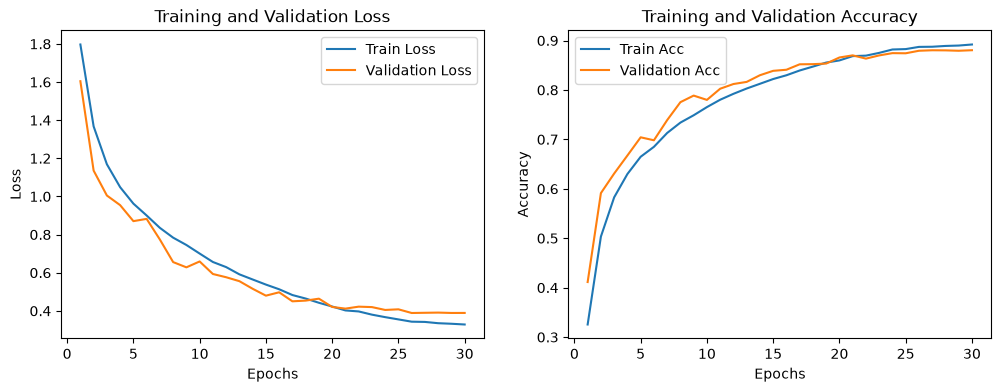

In [27]:
import copy
import time

train_losses, val_losses = [], []
train_accs, val_accs = [], []  # [改進] 同時記錄準確率
best_val_acc, best_state = 0.0, None

for epoch in range(num_epochs):
    start = time.time()
    model.train()
    running_loss = 0.0
    correct, total = 0, 0
    # TODO4: 請實作 training 流程
    # [AI 輔助] 此段由 Claude (Anthropic) 協助撰寫
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    train_losses.append(running_loss / len(train_loader))
    train_accs.append(correct / total)
    scheduler.step()

    # 驗證模型
    model.eval()
    val_loss = 0.0
    correct, total = 0, 0
    # TODO5: 請實作 validation 流程
    # [AI 輔助] 此段由 Claude (Anthropic) 協助撰寫
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            val_loss += criterion(outputs, labels).item()
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    val_losses.append(val_loss / len(val_loader))
    val_accs.append(correct / total)

    # [改進] 保留 validation 準確率最高的權重
    if val_accs[-1] > best_val_acc:
        best_val_acc = val_accs[-1]
        best_state = copy.deepcopy(model.state_dict())

    print(f'Epoch {epoch+1}/{num_epochs}, Train Loss: {train_losses[-1]:.4f}, '
      f'Val Loss: {val_losses[-1]:.4f}, Train Acc: {train_accs[-1]:.4f}, '
      f'Val Acc: {val_accs[-1]:.4f} ({time.time() - start:.0f}s)')

model.load_state_dict(best_state)
print(f'Best Val Acc: {best_val_acc:.4f}')

# 繪製 loss 與 accuracy 的歷史記錄圖
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, num_epochs+1), train_losses, label='Train Loss')
axes[0].plot(range(1, num_epochs+1), val_losses, label='Validation Loss')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].set_title('Training and Validation Loss')
axes[1].plot(range(1, num_epochs+1), train_accs, label='Train Acc')
axes[1].plot(range(1, num_epochs+1), val_accs, label='Validation Acc')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].set_title('Training and Validation Accuracy')
plt.show()

In [28]:
model.eval()
predictions = []
test_loss = 0.0 # 在 test 的時候其實不用算 loss，因為通常我們沒有 test set 的標準答案
test_losses = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        tmp_pred = outputs.argmax(dim=1) # tmp_pred 的型態是 tensor
        predictions.extend(tmp_pred.tolist()) # 如果用 append 的話會變成 [[1, 2, 3], [4, 5, 6]]

        loss = criterion(outputs, labels)
        test_loss += loss.item()
test_losses.append(test_loss / len(test_loader))

In [29]:
# test_labels = [example[1] for example in test_dataset]

In [30]:
accuracy_score(test_labels, predictions)

0.8794

In [31]:
# [改進] 計算訓練集準確率（使用不做資料擴增的版本）
# [AI 輔助] 此段由 Claude (Anthropic) 協助撰寫
train_eval_loader = torch.utils.data.DataLoader(train_eval_dataset, batch_size=test_batch_size, shuffle=False)
correct = 0
with torch.no_grad():
    for images, labels in train_eval_loader:
        outputs = model(images.to(device))
        correct += (outputs.argmax(dim=1).cpu() == labels).sum().item()
print(f'Train Acc: {correct / len(train_eval_dataset):.4f}')
print(f'Val Acc:   {best_val_acc:.4f}')
print(f'Test Acc:  {accuracy_score(test_labels, predictions):.4f}')

Train Acc: 0.9307
Val Acc:   0.8804
Test Acc:  0.8794


## 錯誤分析
使用上面訓練好的 ImprovedCNN（validation 最佳權重）分析在測試集上的錯誤。圖片會存到 `figures/` 供報告使用。

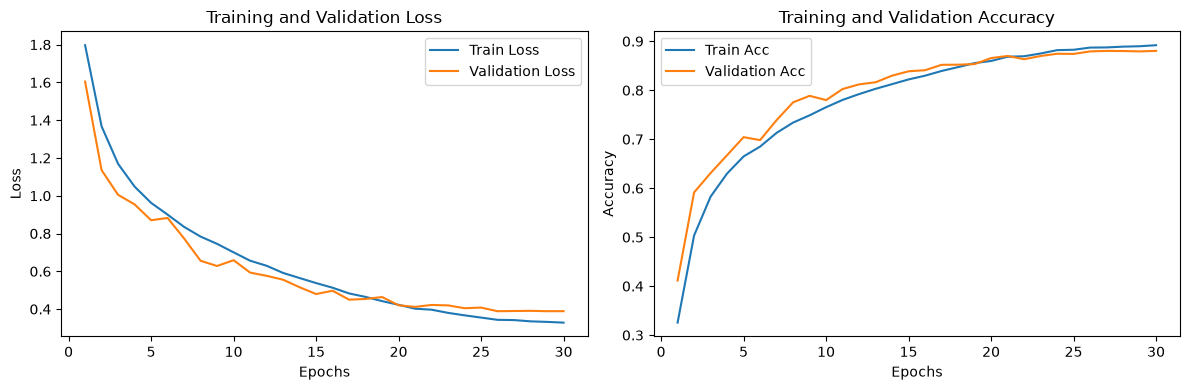

              precision    recall  f1-score   support

    airplane     0.8732    0.9020    0.8874      1000
  automobile     0.9498    0.9470    0.9484      1000
        bird     0.8652    0.8150    0.8393      1000
         cat     0.7765    0.7190    0.7466      1000
        deer     0.8566    0.8900    0.8730      1000
         dog     0.8103    0.8200    0.8151      1000
        frog     0.8830    0.9360    0.9087      1000
       horse     0.9127    0.8890    0.9007      1000
        ship     0.9281    0.9430    0.9355      1000
       truck     0.9321    0.9330    0.9325      1000

    accuracy                         0.8794     10000
   macro avg     0.8788    0.8794    0.8787     10000
weighted avg     0.8788    0.8794    0.8787     10000



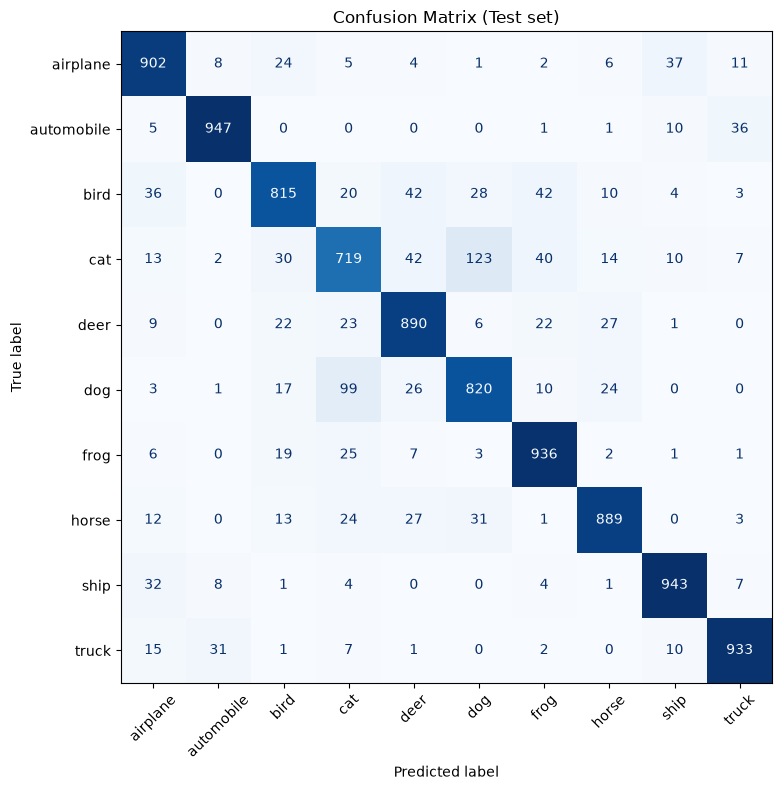

In [32]:
# [AI 輔助] 此段由 Claude (Anthropic) 協助撰寫
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

os.makedirs("figures", exist_ok=True)

# 存下訓練曲線（上面訓練時畫的那張）
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, num_epochs+1), train_losses, label='Train Loss')
axes[0].plot(range(1, num_epochs+1), val_losses, label='Validation Loss')
axes[0].set_xlabel('Epochs'); axes[0].set_ylabel('Loss'); axes[0].legend(); axes[0].set_title('Training and Validation Loss')
axes[1].plot(range(1, num_epochs+1), train_accs, label='Train Acc')
axes[1].plot(range(1, num_epochs+1), val_accs, label='Validation Acc')
axes[1].set_xlabel('Epochs'); axes[1].set_ylabel('Accuracy'); axes[1].legend(); axes[1].set_title('Training and Validation Accuracy')
plt.tight_layout()
plt.savefig("figures/training_curve.png", dpi=150)
plt.show()

# 各類別的 precision / recall / f1
print(classification_report(test_labels, predictions, target_names=label_names, digits=4))

# Confusion matrix
cm = confusion_matrix(test_labels, predictions)
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=label_names).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title("Confusion Matrix (Test set)")
plt.tight_layout()
plt.savefig("figures/confusion_matrix.png", dpi=150)
plt.show()

cat         0.7190
bird        0.8150
dog         0.8200
horse       0.8890
deer        0.8900
airplane    0.9020
truck       0.9330
frog        0.9360
ship        0.9430
automobile  0.9470

最常搞混的前 10 組 (真實 → 預測)：
       cat → dog        123 張
       dog → cat        99 張
       cat → deer       42 張
      bird → frog       42 張
      bird → deer       42 張
       cat → frog       40 張
  airplane → ship       37 張
      bird → airplane   36 張
automobile → truck      36 張
      ship → airplane   32 張


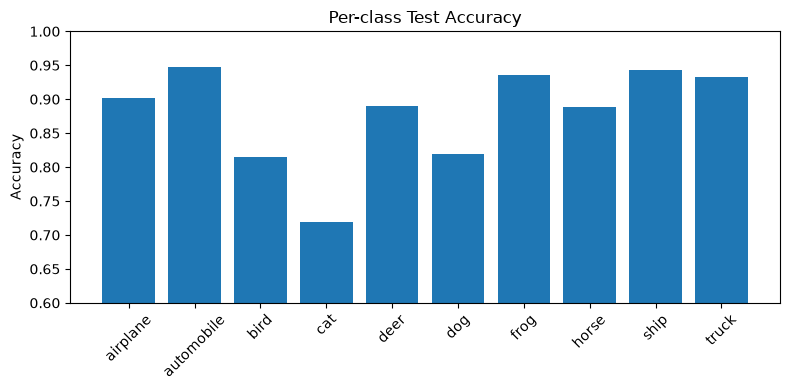

In [33]:
# 各類別準確率與最常被搞混的類別組合
# [AI 輔助] 此段由 Claude (Anthropic) 協助撰寫
per_class_acc = cm.diagonal() / cm.sum(axis=1)
for name, acc in sorted(zip(label_names, per_class_acc), key=lambda x: x[1]):
    print(f"{name:<11s} {acc:.4f}")

confusions = [(cm[i, j], label_names[i], label_names[j]) for i in range(10) for j in range(10) if i != j]
print("\n最常搞混的前 10 組 (真實 → 預測)：")
for count, true_name, pred_name in sorted(confusions, reverse=True)[:10]:
    print(f"{true_name:>10s} → {pred_name:<10s} {count} 張")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(label_names, per_class_acc)
ax.set_ylim(0.6, 1.0)
ax.set_ylabel("Accuracy")
ax.set_title("Per-class Test Accuracy")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("figures/per_class_acc.png", dpi=150)
plt.show()

測試集錯誤數：1206 / 10000


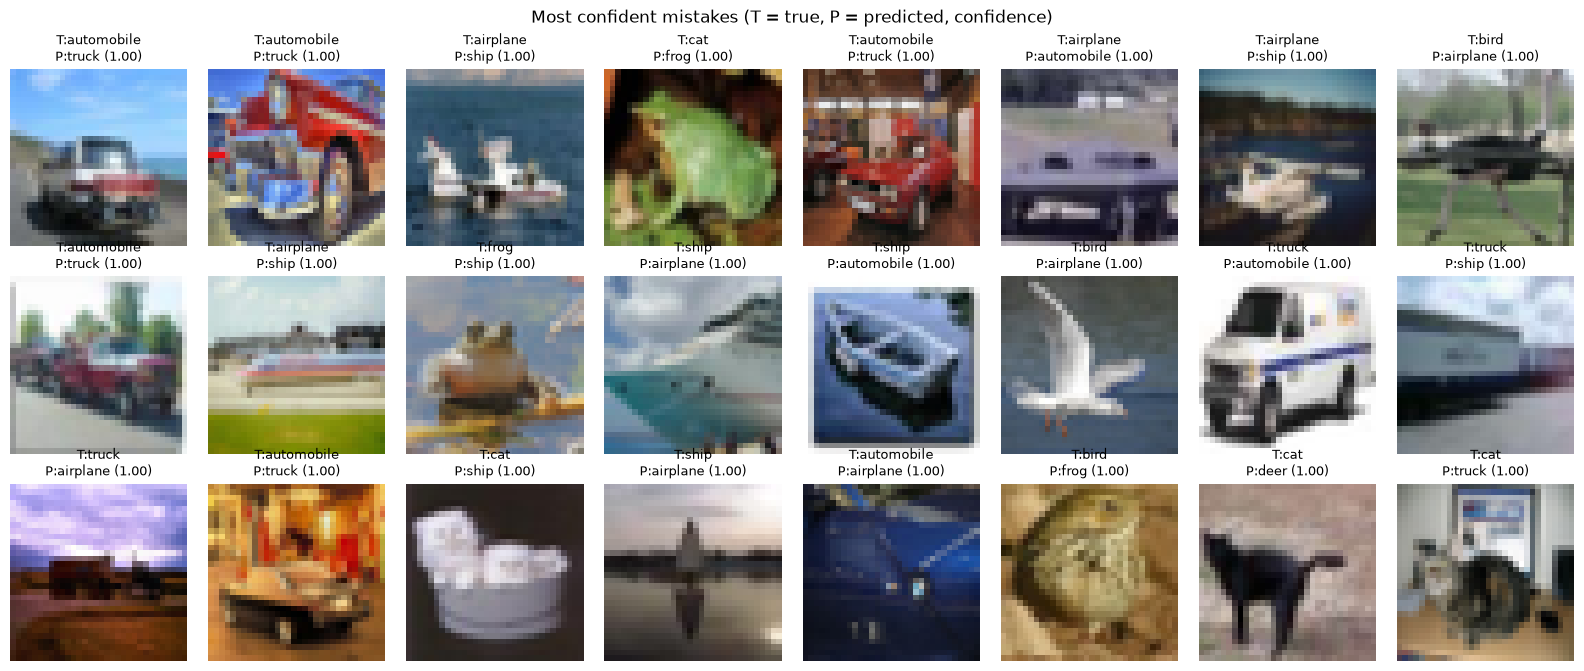

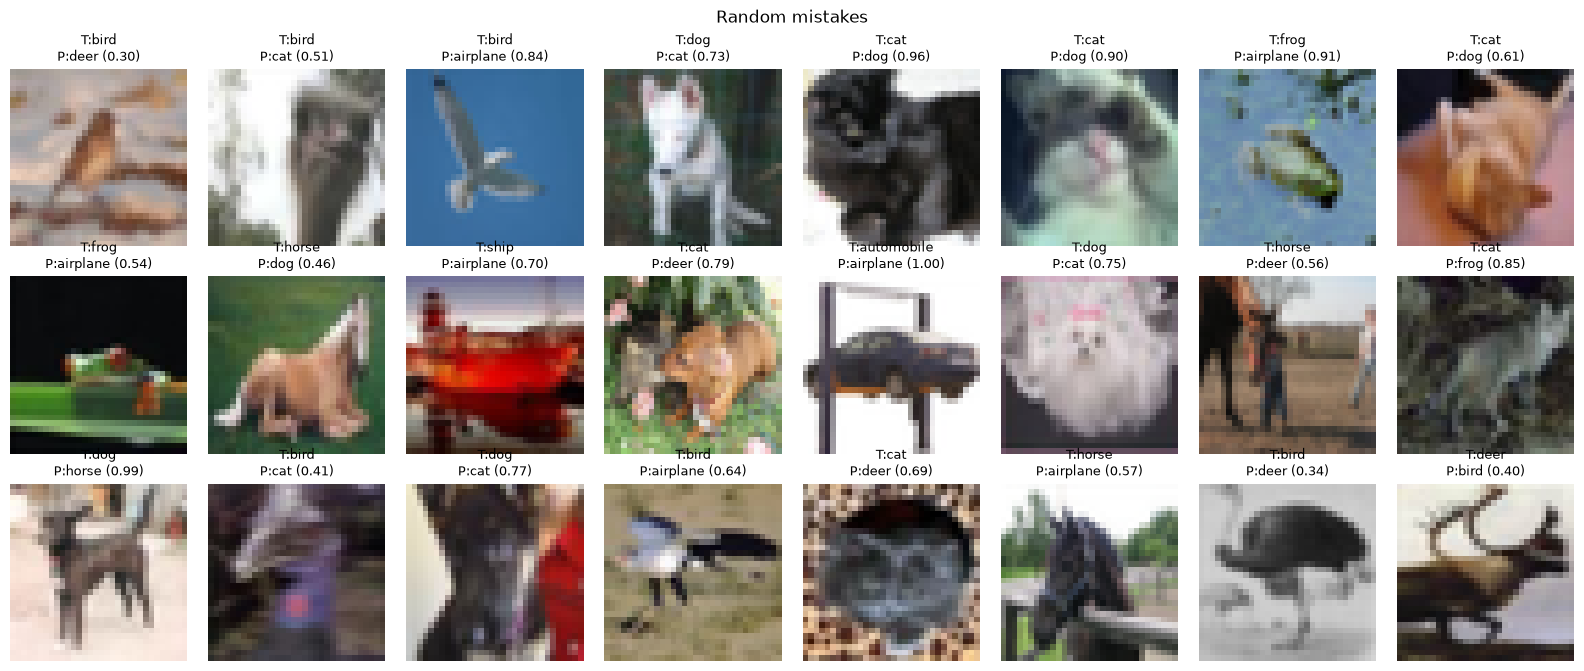

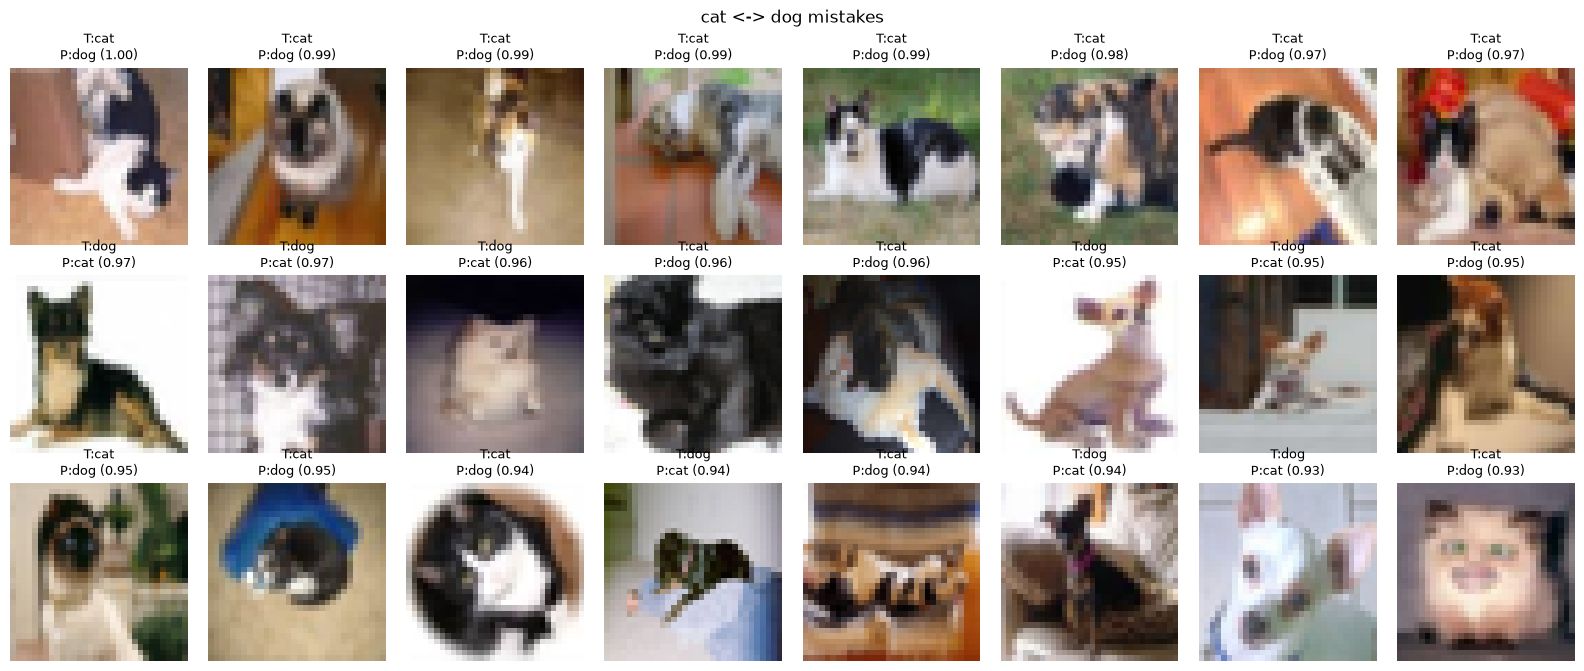

In [34]:
# 錯誤圖片：信心最高的錯誤（模型很確定但答錯）
# [AI 輔助] 此段由 Claude (Anthropic) 協助撰寫
model.eval()
all_probs = []
with torch.no_grad():
    for images, _ in test_loader:
        all_probs.append(torch.softmax(model(images.to(device)), dim=1).cpu())
all_probs = torch.cat(all_probs)
confidence, pred_tensor = all_probs.max(dim=1)
labels_tensor = torch.tensor(test_labels)

wrong_idx = (pred_tensor != labels_tensor).nonzero().squeeze(1)
wrong_idx = wrong_idx[confidence[wrong_idx].argsort(descending=True)]
print(f"測試集錯誤數：{len(wrong_idx)} / {len(test_labels)}")


def show_grid(indices, title, filename):
    fig, axes = plt.subplots(3, 8, figsize=(16, 6.8))
    for ax, i in zip(axes.flat, indices):
        i = int(i)
        ax.imshow(test_dataset.images[i])
        ax.set_title(f"T:{label_names[test_labels[i]]}\nP:{label_names[pred_tensor[i]]} ({confidence[i]:.2f})", fontsize=9)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(f"figures/{filename}", dpi=150)
    plt.show()


show_grid(wrong_idx[:24], "Most confident mistakes (T = true, P = predicted, confidence)", "wrong_confident.png")

# 隨機抽樣的錯誤，看一般情況
g = torch.Generator().manual_seed(SEED)
show_grid(wrong_idx[torch.randperm(len(wrong_idx), generator=g)[:24]], "Random mistakes", "wrong_random.png")

# cat ↔ dog 的錯誤
cat, dog = label_names.index("cat"), label_names.index("dog")
cat_dog = [int(i) for i in wrong_idx if {test_labels[int(i)], int(pred_tensor[i])} == {cat, dog}]
show_grid(cat_dog[:24], "cat <-> dog mistakes", "wrong_cat_dog.png")

## 實驗設定分析
為了比較不同設定，以下每組實驗都使用**相同的資料切分、相同 seed、訓練 15 epochs**（比主模型的 30 epochs 少，以節省時間），只改變一個變因：

1. **模型層數**：每個 stage 的 conv 層數 1 / 2 / 3（共 3 / 6 / 9 層 conv）
2. **Optimizer**：SGD (momentum) / Adam / AdamW
3. **資料擴增**：無 / 只有水平翻轉 / 隨機裁切 + 水平翻轉

基準設定：6 層 conv、AdamW、隨機裁切 + 水平翻轉（三張表共用這組結果）。

In [35]:
# [AI 輔助] 此段由 Claude (Anthropic) 協助撰寫
EXP_EPOCHS = 15


class VGGStyleCNN(torch.nn.Module):
    """3 個 stage，每個 stage 有 convs_per_stage 層 conv，接 2x2 max pooling。
    convs_per_stage=2 時與 ImprovedCNN 結構相同"""

    def __init__(self, convs_per_stage=2, num_classes=10, channels=(64, 128, 256), dropouts=(0.1, 0.2, 0.3)):
        super().__init__()
        layers, in_ch = [], 3
        for out_ch, p in zip(channels, dropouts):
            for _ in range(convs_per_stage):
                layers.append(conv_block(in_ch, out_ch))
                in_ch = out_ch
            layers += [torch.nn.MaxPool2d(2), torch.nn.Dropout(p)]
        self.features = torch.nn.Sequential(*layers)
        self.classifier = torch.nn.Sequential(
            torch.nn.Flatten(),
            torch.nn.Linear(channels[-1] * 4 * 4, 512),
            torch.nn.ReLU(inplace=True),
            torch.nn.Dropout(0.5),
            torch.nn.Linear(512, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


flip_transform = torchvision.transforms.Compose([
    torchvision.transforms.RandomHorizontalFlip(),
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(mean=CIFAR10_MEAN, std=CIFAR10_STD),
])

OPTIMIZERS = {
    "SGD":   lambda params: torch.optim.SGD(params, lr=0.05, momentum=0.9, weight_decay=weight_decay),
    "Adam":  lambda params: torch.optim.Adam(params, lr=LR),
    "AdamW": lambda params: torch.optim.AdamW(params, lr=LR, weight_decay=weight_decay),
}
AUGMENTATIONS = {
    "None": test_transform,
    "Flip": flip_transform,
    "Crop+Flip": train_transform,
}


def evaluate(net, loader):
    net.eval()
    correct, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = net(images)
            loss_sum += criterion(outputs, labels).item()
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return loss_sum / len(loader), correct / total


def run_experiment(convs_per_stage=2, optimizer_name="AdamW", augmentation="Crop+Flip", epochs=EXP_EPOCHS):
    torch.manual_seed(SEED)
    exp_train = TransformSubset(full_train_dataset, train_split.indices, AUGMENTATIONS[augmentation])
    exp_loader = torch.utils.data.DataLoader(exp_train, batch_size=train_batch_size, shuffle=True)

    net = VGGStyleCNN(convs_per_stage).to(device)
    opt = OPTIMIZERS[optimizer_name](net.parameters())
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    history = {"train_acc": [], "val_acc": [], "train_loss": [], "val_loss": []}
    best_val, best_state = 0.0, None
    start = time.time()
    for epoch in range(epochs):
        net.train()
        correct, total, loss_sum = 0, 0, 0.0
        for images, labels in exp_loader:
            images, labels = images.to(device), labels.to(device)
            opt.zero_grad()
            outputs = net(images)
            loss = criterion(outputs, labels)
            loss.backward()
            opt.step()
            loss_sum += loss.item()
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
        sched.step()
        val_loss, val_acc = evaluate(net, val_loader)
        history["train_loss"].append(loss_sum / len(exp_loader))
        history["train_acc"].append(correct / total)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if val_acc > best_val:
            best_val, best_state = val_acc, copy.deepcopy(net.state_dict())

    net.load_state_dict(best_state)
    _, train_acc = evaluate(net, train_eval_loader)
    _, test_acc = evaluate(net, test_loader)
    result = {
        "Conv layers": convs_per_stage * 3,
        "Optimizer": optimizer_name,
        "Augmentation": augmentation,
        "Params (M)": round(sum(p.numel() for p in net.parameters()) / 1e6, 2),
        "Train Acc": round(train_acc, 4),
        "Best Val Acc": round(best_val, 4),
        "Test Acc": round(test_acc, 4),
        "Train-Test Gap": round(train_acc - test_acc, 4),
        "Time (s)": round(time.time() - start),
        "history": history,
    }
    print(f"[{result['Conv layers']} conv / {optimizer_name} / {augmentation}] "
          f"train {train_acc:.4f}, val {best_val:.4f}, test {test_acc:.4f} ({result['Time (s)']}s)")
    return result

In [36]:
# 執行所有實驗（約 20 分鐘）
# [AI 輔助] 此段由 Claude (Anthropic) 協助撰寫
experiments = {}
configs = [
    (2, "AdamW", "Crop+Flip"),  # 基準設定
    (1, "AdamW", "Crop+Flip"), (3, "AdamW", "Crop+Flip"),  # 層數
    (2, "SGD", "Crop+Flip"), (2, "Adam", "Crop+Flip"),      # optimizer
    (2, "AdamW", "None"), (2, "AdamW", "Flip"),             # 資料擴增
]
for cfg in configs:
    experiments[cfg] = run_experiment(*cfg)

[6 conv / AdamW / Crop+Flip] train 0.8643, val 0.8367, test 0.8319 (186s)


[3 conv / AdamW / Crop+Flip] train 0.7869, val 0.7716, test 0.7640 (140s)


[9 conv / AdamW / Crop+Flip] train 0.8855, val 0.8509, test 0.8516 (243s)


[6 conv / SGD / Crop+Flip] train 0.8925, val 0.8578, test 0.8533 (191s)


[6 conv / Adam / Crop+Flip] train 0.8667, val 0.8383, test 0.8350 (191s)


[6 conv / AdamW / None] train 0.9433, val 0.8550, test 0.8546 (157s)


[6 conv / AdamW / Flip] train 0.9123, val 0.8562, test 0.8575 (168s)


表 1：模型層數比較（AdamW、Crop+Flip）
             Params (M)  Train Acc  Best Val Acc  Test Acc  Train-Test Gap  Time (s)
Conv layers                                                                         
3                  2.47     0.7869        0.7716    0.7640          0.0229       140
6                  3.25     0.8643        0.8367    0.8319          0.0324       186
9                  4.02     0.8855        0.8509    0.8516          0.0339       243

表 2：Optimizer 比較（6 層 conv、Crop+Flip）
           Params (M)  Train Acc  Best Val Acc  Test Acc  Train-Test Gap  Time (s)
Optimizer                                                                         
SGD              3.25     0.8925        0.8578    0.8533          0.0392       191
Adam             3.25     0.8667        0.8383    0.8350          0.0317       191
AdamW            3.25     0.8643        0.8367    0.8319          0.0324       186

表 3：資料擴增比較（6 層 conv、AdamW）
              Params (M)  Train Acc  Best Val Acc  Test Acc  Train

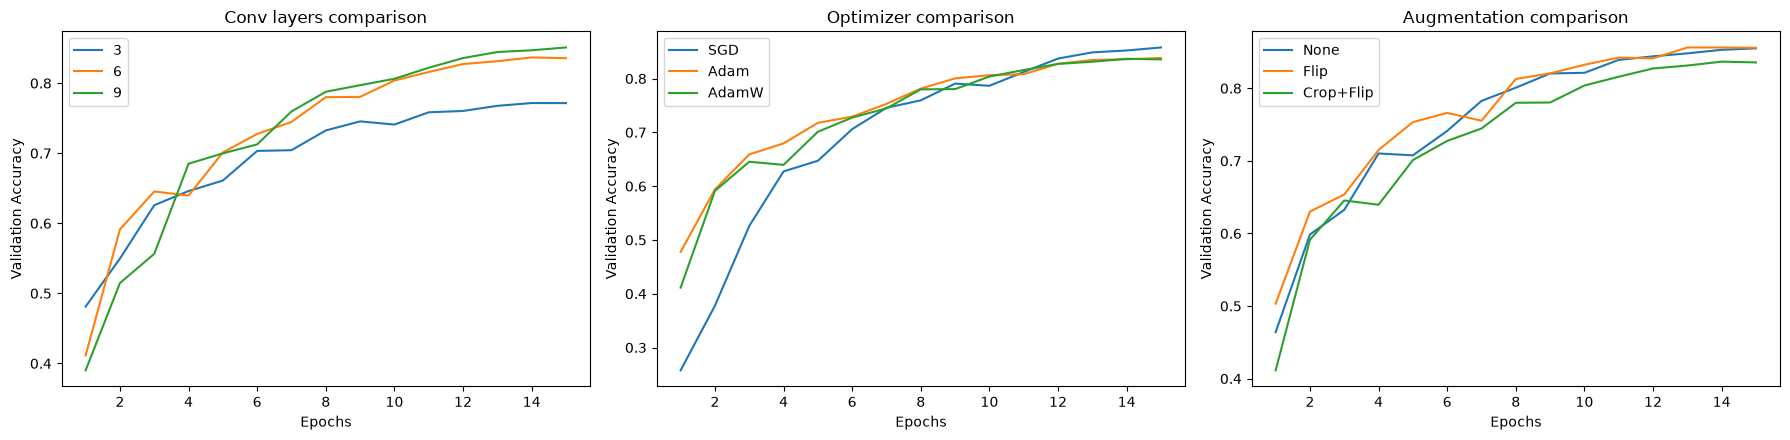

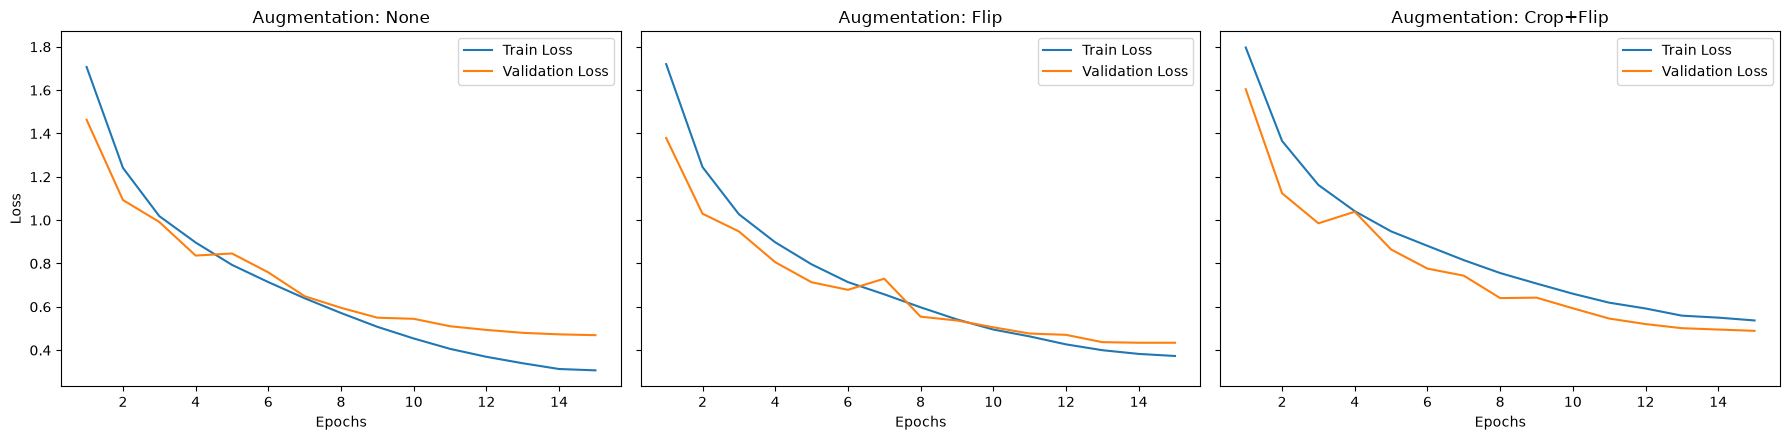

In [37]:
# 三張比較表格
# [AI 輔助] 此段由 Claude (Anthropic) 協助撰寫
import pandas as pd

COLUMNS = ["Params (M)", "Train Acc", "Best Val Acc", "Test Acc", "Train-Test Gap", "Time (s)"]
TABLES = {
    "表 1：模型層數比較（AdamW、Crop+Flip）": ("Conv layers", [(1, "AdamW", "Crop+Flip"), (2, "AdamW", "Crop+Flip"), (3, "AdamW", "Crop+Flip")]),
    "表 2：Optimizer 比較（6 層 conv、Crop+Flip）": ("Optimizer", [(2, "SGD", "Crop+Flip"), (2, "Adam", "Crop+Flip"), (2, "AdamW", "Crop+Flip")]),
    "表 3：資料擴增比較（6 層 conv、AdamW）": ("Augmentation", [(2, "AdamW", "None"), (2, "AdamW", "Flip"), (2, "AdamW", "Crop+Flip")]),
}

for title, (key, cfgs) in TABLES.items():
    df = pd.DataFrame([{key: experiments[c][key], **{k: experiments[c][k] for k in COLUMNS}} for c in cfgs]).set_index(key)
    print(title)
    print(df.to_string())
    print()

# 存成 CSV，方便貼進報告
pd.DataFrame([{k: v for k, v in r.items() if k != "history"} for r in experiments.values()]).to_csv("figures/experiments.csv", index=False)

# 驗證準確率曲線
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (title, (key, cfgs)) in zip(axes, TABLES.items()):
    for c in cfgs:
        ax.plot(range(1, EXP_EPOCHS + 1), experiments[c]["history"]["val_acc"], label=str(experiments[c][key]))
    ax.set_title(f"{key} comparison")
    ax.set_xlabel("Epochs")
    ax.set_ylabel("Validation Accuracy")
    ax.legend()
plt.tight_layout()
plt.savefig("figures/experiments_val_acc.png", dpi=150)
plt.show()

# 資料擴增對 overfitting 的影響：train vs val loss
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, c in zip(axes, TABLES["表 3：資料擴增比較（6 層 conv、AdamW）"][1]):
    h = experiments[c]["history"]
    ax.plot(range(1, EXP_EPOCHS + 1), h["train_loss"], label="Train Loss")
    ax.plot(range(1, EXP_EPOCHS + 1), h["val_loss"], label="Validation Loss")
    ax.set_title(f"Augmentation: {c[2]}")
    ax.set_xlabel("Epochs")
    ax.legend()
axes[0].set_ylabel("Loss")
plt.tight_layout()
plt.savefig("figures/augmentation_loss.png", dpi=150)
plt.show()